<a href="https://colab.research.google.com/github/contreras-juan/procesamiento_lenguaje_natural/blob/main/Cuadernos/09_Viterbi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 style="color: #FECB05; text-align: center;">Algoritmo de Viterbi</h1>

<h2 style="color: #007ACC;">Autores</h2>

- [Juan Felipe Contreras Alcívar](https://www.linkedin.com/in/juanf-contreras/)

---

<h2 style="color: #007ACC;">Tabla de contenido</h2>

- [<span style="color: #005C99;">Introducción</span>](#introduccion)
- [<span style="color: #005C99;">Decodificación en un HMM</span>](#decodificacion-en-un-hmm)
- [<span style="color: #005C99;">El algoritmo de Viterbi</span>](#el-algoritmo-de-viterbi)
- [<span style="color: #005C99;">Ejemplo paso a paso</span>](#ejemplo-paso-a-paso)
- [<span style="color: #005C99;">Implementación en espacio logarítmico</span>](#implementacion-en-espacio-logaritmico)
- [<span style="color: #005C99;">Etiquetado gramatical del español con un HMM</span>](#etiquetado-gramatical-del-espanol-con-un-hmm)
- [<span style="color: #005C99;">Palabras desconocidas</span>](#palabras-desconocidas)
- [<span style="color: #005C99;">Evaluación y análisis de errores</span>](#evaluacion-y-analisis-de-errores)
- [<span style="color: #005C99;">Referencias</span>](#referencias)

---

<h2 style="color: #007ACC;">Instalación de librerías</h2>

Ejecuta esta celda si trabajas en Google Colab o en un entorno nuevo.

In [1]:
# Instalación de librerías necesarias para esta sesión
# (útil en Google Colab o en un entorno nuevo)
%pip install -q numpy pandas matplotlib seaborn nltk

Note: you may need to restart the kernel to use updated packages.


In [2]:
import itertools
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import cess_esp

SEED = 42
np.random.seed(SEED)

_ = nltk.download("cess_esp", quiet=True)

<a id="introduccion"></a>
<h2 style="color: #007ACC;">Introducción</h2>

En el cuaderno 08 construimos un HMM para el español: una matriz de transición $A$ entre etiquetas gramaticales y una matriz de emisión $B$ de palabras. Ahora queremos **usarlo para etiquetar**: dada una oración nueva, encontrar su secuencia de etiquetas.

Este es el **problema de decodificación**, el segundo de los tres problemas fundamentales de los HMM. Lo resuelve el **algoritmo de Viterbi** (1967), uno de los algoritmos más influyentes de la ingeniería: además de en PLN, se usa en reconocimiento de voz, en bioinformática (alineamiento de secuencias genéticas) y en la decodificación de señales en telefonía móvil y comunicaciones satelitales.

<a id="decodificacion-en-un-hmm"></a>
<h2 style="color: #007ACC;">Decodificación en un HMM</h2>

Dada una secuencia de observaciones $O = o_1, \dots, o_T$, buscamos la secuencia de estados más probable:

$$\hat{Q} = \arg\max_{Q} P(Q \mid O) = \arg\max_{Q} \frac{P(O, Q)}{P(O)} = \arg\max_{Q} P(O, Q)$$

con $P(O, Q) = \pi_{q_1} b_{q_1}(o_1) \prod_{t=2}^{T} a_{q_{t-1} q_t} b_{q_t}(o_t)$.

¿Por qué no elegir simplemente la etiqueta más probable de cada palabra por separado? Porque las decisiones **interactúan**: en *"la vieja cierra la puerta"*, que *vieja* sea sustantivo hace más probable que *cierra* sea verbo, y viceversa. Hay que optimizar la secuencia completa. Pero, como en el problema de verosimilitud, hay $N^T$ secuencias posibles.

Retomemos el ejemplo de los helados del cuaderno 08:

In [3]:
estados = ["C", "F"]          # caluroso, frío
observaciones = [1, 2, 3]     # helados comidos
pi = np.array([0.8, 0.2])
A = np.array([[0.6, 0.4],
              [0.5, 0.5]])
B = np.array([[0.2, 0.4, 0.4],
              [0.5, 0.4, 0.1]])


def prob_conjunta(obs, q):
    p = pi[q[0]] * B[q[0], obs[0]]
    for t in range(1, len(obs)):
        p *= A[q[t - 1], q[t]] * B[q[t], obs[t]]
    return p


obs = [observaciones.index(o) for o in [3, 1, 3]]
candidatas = {"".join(estados[i] for i in q): prob_conjunta(obs, q) for q in itertools.product(range(2), repeat=3)}
mejor = max(candidatas, key=candidatas.get)
print(pd.Series(candidatas).sort_values(ascending=False).round(5).to_string())
print(f"\nSecuencia más probable por fuerza bruta: {mejor}")

CFC    0.01280
CCC    0.00922
CFF    0.00320
CCF    0.00154
FFC    0.00100
FCC    0.00048
FFF    0.00025
FCF    0.00008

Secuencia más probable por fuerza bruta: CFC


<a id="el-algoritmo-de-viterbi"></a>
<h2 style="color: #007ACC;">El algoritmo de Viterbi</h2>

Viterbi tiene la misma estructura que el algoritmo forward, pero cambia la **suma** por un **máximo**. Definimos:

$$v_t(j) = \max_{q_1, \dots, q_{t-1}} P(o_1, \dots, o_t, q_1, \dots, q_{t-1}, q_t = j)$$

la probabilidad del **mejor camino** que termina en el estado $j$ en el instante $t$. La clave es el **principio de optimalidad**: el mejor camino que llega a $j$ en $t$ tiene que pasar por el mejor camino que llega a algún estado $i$ en $t-1$. Por eso basta con guardar, para cada estado, el mejor camino que llega a él.

1. **Inicialización:** $v_1(j) = \pi_j\, b_j(o_1)$
2. **Recursión:**
   $$v_t(j) = \max_{i} \; v_{t-1}(i)\, a_{ij}\, b_j(o_t), \qquad \text{bp}_t(j) = \arg\max_{i} \; v_{t-1}(i)\, a_{ij}$$
   El **puntero hacia atrás** $\text{bp}_t(j)$ recuerda de qué estado venía el mejor camino.
3. **Terminación:** $P^* = \max_j v_T(j)$, con último estado $q_T^* = \arg\max_j v_T(j)$.
4. **Reconstrucción:** se siguen los punteros hacia atrás: $q_{t-1}^* = \text{bp}_t(q_t^*)$.

| | Forward | Viterbi |
|---|---------|---------|
| Pregunta | $P(O)$ | $\arg\max_Q P(O, Q)$ |
| Operación | $\sum_i$ | $\max_i$ (y se guarda el $\arg\max_i$) |
| Costo | $O(N^2 T)$ | $O(N^2 T)$ |

<a id="ejemplo-paso-a-paso"></a>
<h2 style="color: #007ACC;">Ejemplo paso a paso</h2>

In [4]:
def viterbi_explicado(obs):
    T, N = len(obs), len(pi)
    v = np.zeros((T, N))
    bp = np.zeros((T, N), dtype=int)
    v[0] = pi * B[:, obs[0]]
    for t in range(1, T):
        for j in range(N):
            candidatos = v[t - 1] * A[:, j] * B[j, obs[t]]
            bp[t, j] = np.argmax(candidatos)
            v[t, j] = candidatos[bp[t, j]]
            detalle = ", ".join(f"desde {estados[i]}: {candidatos[i]:.5f}" for i in range(N))
            print(f"t={t + 1}, estado {estados[j]}: {detalle} -> mejor {estados[bp[t, j]]}")
    camino = [int(np.argmax(v[-1]))]
    for t in range(T - 1, 0, -1):
        camino.append(bp[t, camino[-1]])
    return camino[::-1], v, bp


camino, v, bp = viterbi_explicado(obs)
print("\nTabla de Viterbi v_t(j):")
print(pd.DataFrame(v, columns=estados, index=[f"t={t + 1} ({o})" for t, o in enumerate([3, 1, 3])]).round(5))
print("\nSecuencia más probable (Viterbi):", "".join(estados[i] for i in camino))

t=2, estado C: desde C: 0.03840, desde F: 0.00200 -> mejor C
t=2, estado F: desde C: 0.06400, desde F: 0.00500 -> mejor C
t=3, estado C: desde C: 0.00922, desde F: 0.01280 -> mejor F
t=3, estado F: desde C: 0.00154, desde F: 0.00320 -> mejor F

Tabla de Viterbi v_t(j):
              C       F
t=1 (3)  0.3200  0.0200
t=2 (1)  0.0384  0.0640
t=3 (3)  0.0128  0.0032

Secuencia más probable (Viterbi): CFC


Viterbi encuentra la misma secuencia que la fuerza bruta, con probabilidad $\max_j v_3(j)$ igual al máximo de la tabla anterior, pero explorando solo $N^2$ combinaciones por paso en lugar de todas las secuencias.

Observa cómo funcionan los punteros. En $t = 3$, el mejor camino que termina en **C** viene de **F** ($0.0128$ frente a $0.00922$ desde C), así que al reconstruir desde el final obtenemos C → F → C. El día con un solo helado se etiqueta como **frío**, pero los dos días con tres helados que lo rodean se mantienen **calurosos**. Viterbi encuentra este equilibrio entre emisiones y transiciones mirando la secuencia completa, no cada día por separado.

<a id="implementacion-en-espacio-logaritmico"></a>
<h2 style="color: #007ACC;">Implementación en espacio logarítmico</h2>

Con oraciones reales los productos de probabilidades provocan *underflow*. Como el logaritmo es creciente, el $\arg\max$ no cambia si trabajamos con log-probabilidades, y los productos se convierten en sumas:

$$\log v_t(j) = \max_i \left[ \log v_{t-1}(i) + \log a_{ij} \right] + \log b_j(o_t)$$

Además, con NumPy podemos calcular todos los estados de un paso a la vez: `log_v[t-1][:, None] + log_A` es una matriz $N \times N$ cuyo elemento $(i, j)$ es el puntaje de llegar a $j$ desde $i$.

In [5]:
def viterbi(log_pi, log_A, log_B_obs):
    """Algoritmo de Viterbi en espacio logarítmico.

    log_pi: (N,) log-probabilidades iniciales.
    log_A: (N, N) log-probabilidades de transición.
    log_B_obs: (T, N) log P(o_t | estado j) para cada posición de la secuencia observada.
    Devuelve la secuencia de estados más probable y su log-probabilidad.
    """
    T, N = log_B_obs.shape
    log_v = np.zeros((T, N))
    bp = np.zeros((T, N), dtype=int)
    log_v[0] = log_pi + log_B_obs[0]
    for t in range(1, T):
        puntajes = log_v[t - 1][:, None] + log_A      # (N, N): desde i hacia j
        bp[t] = puntajes.argmax(axis=0)
        log_v[t] = puntajes.max(axis=0) + log_B_obs[t]
    camino = [int(log_v[-1].argmax())]
    for t in range(T - 1, 0, -1):
        camino.append(int(bp[t, camino[-1]]))
    return camino[::-1], float(log_v[-1].max())


camino, log_p = viterbi(np.log(pi), np.log(A), np.log(B[:, obs].T))
print("".join(estados[i] for i in camino), f"P* = {np.exp(log_p):.5f}")

CFC P* = 0.01280


<a id="etiquetado-gramatical-del-espanol-con-un-hmm"></a>
<h2 style="color: #007ACC;">Etiquetado gramatical del español con un HMM</h2>

Volvamos a CESS-ESP. Esta vez **conservamos las mayúsculas**, que nos servirán para reconocer nombres propios.

In [6]:
# --- Carga de CESS-ESP con etiquetas gramaticales simplificadas -------------------------
# Las etiquetas originales siguen el estándar EAGLES (p. ej. "ncms000" = nombre común masculino
# singular). Las reducimos a categorías universales usando su primera letra.
MAPA_EAGLES = {"n": "NOUN", "v": "VERB", "a": "ADJ", "d": "DET", "s": "ADP", "r": "ADV", "p": "PRON",
               "c": "CONJ", "f": "PUNCT", "z": "NUM", "w": "NUM", "i": "INTJ"}


def etiqueta_universal(eagles):
    eagles = eagles.lower()
    if eagles.startswith("np"):
        return "PROPN"
    if eagles.startswith(("va", "vs")):  # haber y ser como auxiliares
        return "AUX"
    return MAPA_EAGLES.get(eagles[0], "X")


SIGNOS = {"-Fpa-": "(", "-Fpt-": ")", "-fe-": '"'}
# Conservamos las mayúsculas: son una pista valiosa para reconocer nombres propios
corpus = [[(SIGNOS.get(w, w), etiqueta_universal(t)) for w, t in s if not w.startswith("*")]
          for s in cess_esp.tagged_sents()]

rng = np.random.default_rng(SEED)
orden = rng.permutation(len(corpus))
corte = int(0.9 * len(corpus))
train = [corpus[i] for i in orden[:corte]]
test = [corpus[i] for i in orden[corte:]]

ETIQUETAS = sorted({t for s in train for _, t in s})
t2i = {t: i for i, t in enumerate(ETIQUETAS)}
print(f"Entrenamiento: {len(train)} oraciones | Prueba: {len(test)} oraciones | {len(ETIQUETAS)} etiquetas")

Entrenamiento: 5427 oraciones | Prueba: 603 oraciones | 14 etiquetas


Estimamos $\pi$ y $A$ contando, como en el cuaderno 08. Para las emisiones usamos las palabras en minúscula y guardamos los conteos; decidiremos cómo tratar las palabras desconocidas en la siguiente sección.

In [7]:
N = len(ETIQUETAS)
c_ini, c_trans = np.zeros(N), np.zeros((N, N))
c_emis = np.zeros(N)
emis = Counter()  # (etiqueta, palabra) -> conteo
for s in train:
    tags = [t2i[t] for _, t in s]
    c_ini[tags[0]] += 1
    for i, j in zip(tags, tags[1:]):
        c_trans[i, j] += 1
    for w, t in s:
        emis[(t2i[t], w.lower())] += 1
        c_emis[t2i[t]] += 1

log_pi = np.log((c_ini + 1e-3) / (c_ini + 1e-3).sum())
log_A = np.log((c_trans + 1e-3) / (c_trans + 1e-3).sum(axis=1, keepdims=True))
vocab_train = {w for _, w in emis}
print(f"Vocabulario de entrenamiento: {len(vocab_train):,} palabras")

Vocabulario de entrenamiento: 22,988 palabras


<a id="palabras-desconocidas"></a>
<h2 style="color: #007ACC;">Palabras desconocidas</h2>

Si una palabra de prueba nunca apareció en entrenamiento, $b_j(w) = 0$ para todas las etiquetas y Viterbi no puede elegir. ¿Cuántas hay?

In [8]:
tokens_test = [w.lower() for s in test for w, _ in s]
desconocidas = [w for w in tokens_test if w not in vocab_train]
print(f"Tokens de prueba desconocidos: {len(desconocidas) / len(tokens_test):.1%}")
print("Ejemplos:", desconocidas[:15])

Tokens de prueba desconocidos: 8.2%
Ejemplos: ['beatriz_ramacciotti', 'prevaleció', 'walter_zinn', 'herb_anderson', 'por_favor', 'imploraba', 'conmovieron', 'vaciar', 'incapacitar', 'destruirle', 'doblegarle', 'honestamente', 'iniciara', 'ilegítima', 'nulos']


Probaremos dos estrategias:

**Estrategia 1 — emisión constante:** para una palabra desconocida, $b_j(w)$ es igual (y pequeña) para todas las etiquetas. Así la decisión queda solo en manos de las transiciones: el contexto gramatical.

**Estrategia 2 — clases de palabras desconocidas por su forma:** la forma de una palabra dice mucho de su categoría, sobre todo en un idioma con morfología rica como el español: *-mente* casi siempre es adverbio, *-ción* sustantivo, *-aron* verbo, una palabra con mayúscula a mitad de oración probablemente es nombre propio. La idea:

1. En entrenamiento, las palabras **raras** (que aparecen una sola vez) se reemplazan por una pseudopalabra que describe su forma: `<UNK-mente>`, `<UNK-ción>`, `<UNK-Mayús>`...
2. Así el HMM aprende $P(\texttt{<UNK-mente>} \mid \text{ADV})$ como cualquier otra emisión.
3. En prueba, cada palabra desconocida se reemplaza por su clase.

In [9]:
SUFIJOS = ["mente", "ción", "sión", "dad", "ismo", "ista", "ando", "iendo", "ado", "ada", "ido", "ida",
           "aron", "ieron", "aba", "ía", "ar", "er", "ir", "oso", "osa", "ble", "s"]


def clase_desconocida(palabra, inicio_oracion):
    if re.fullmatch(r"[\d.,:/%-]+", palabra):
        return "<UNK-NUM>"
    if "_" in palabra:                      # expresiones de varias palabras de CESS
        return "<UNK-Multi-Mayús>" if palabra[0].isupper() else "<UNK-Multi>"
    if palabra[0].isupper() and not inicio_oracion:
        return "<UNK-Mayús>"
    p = palabra.lower()
    for suf in SUFIJOS:
        if p.endswith(suf):
            return f"<UNK-{suf}>"
    return "<UNK>"


for w, ini in [("rápidamente", False), ("globalización", False), ("Kabul", False), ("Kabul", True),
               ("1.250", False), ("Banco_Central", False), ("reestructuraron", False), ("tlön", False)]:
    print(f"{w:<16} inicio={ini!s:<5} -> {clase_desconocida(w, ini)}")

rápidamente      inicio=False -> <UNK-mente>
globalización    inicio=False -> <UNK-ción>
Kabul            inicio=False -> <UNK-Mayús>
Kabul            inicio=True  -> <UNK>
1.250            inicio=False -> <UNK-NUM>
Banco_Central    inicio=False -> <UNK-Multi-Mayús>
reestructuraron  inicio=False -> <UNK-aron>
tlön             inicio=False -> <UNK>


In [10]:
frec_train = Counter(w.lower() for s in train for w, _ in s)


def normalizar(oracion, vocab):
    """Palabras a minúscula; las que no están en el vocabulario, a su clase de forma."""
    return [w.lower() if w.lower() in vocab else clase_desconocida(w, i == 0) for i, w in enumerate(oracion)]


VOCAB = {w for w, c in frec_train.items() if c > 1}   # las palabras vistas una vez se tratan como raras
emis_unk = Counter()
for s in train:
    palabras, tags = zip(*s)
    for w, t in zip(normalizar(palabras, VOCAB), tags):
        emis_unk[(t2i[t], w)] += 1

clases = sorted({w for _, w in emis_unk if w.startswith("<UNK")})
tabla = pd.DataFrame({c: [emis_unk[(t2i[t], c)] for t in ETIQUETAS] for c in clases}, index=ETIQUETAS)
tabla[["<UNK-mente>", "<UNK-ción>", "<UNK-aron>", "<UNK-Mayús>", "<UNK-NUM>", "<UNK-ado>", "<UNK>"]]

,<UNK-mente>,<UNK-ción>,<UNK-aron>,<UNK-Mayús>,<UNK-NUM>,<UNK-ado>,<UNK>
ADJ,2,1,0,2,0,174,888
ADP,0,0,0,0,0,0,0
ADV,153,0,0,0,0,0,7
AUX,0,0,0,0,0,0,4
CONJ,0,0,0,0,0,0,0
DET,0,0,0,0,0,0,4
INTJ,0,0,0,4,0,0,3
NOUN,0,179,0,21,0,34,1289
NUM,0,0,0,3,410,0,46
PRON,0,0,0,0,0,0,7


La tabla confirma la intuición: `<UNK-mente>` es casi siempre adverbio, `<UNK-ción>` sustantivo, `<UNK-aron>` verbo, `<UNK-Mayús>` nombre propio. Construimos la función que calcula la matriz de log-emisiones $(T \times N)$ de una oración para cada estrategia:

In [11]:
def log_emisiones_constante(oracion, alpha=1e-3):
    palabras = [w.lower() for w in oracion]
    V = len(vocab_train)
    M = np.zeros((len(palabras), N))
    for t, w in enumerate(palabras):
        if w in vocab_train:
            M[t] = np.log([(emis[(j, w)] + alpha) / (c_emis[j] + alpha * V) for j in range(N)])
        else:
            M[t] = np.log(1e-6)  # igual para todas las etiquetas
    return M


c_emis_unk = np.array([sum(c for (j, _), c in emis_unk.items() if j == i) for i in range(N)])
V_unk = len({w for _, w in emis_unk})


def log_emisiones_clases(oracion, alpha=1e-3):
    palabras = normalizar(oracion, VOCAB)
    return np.array([[np.log((emis_unk[(j, w)] + alpha) / (c_emis_unk[j] + alpha * V_unk)) for j in range(N)]
                     for w in palabras])


def etiquetar_hmm(oracion, log_emisiones):
    camino, _ = viterbi(log_pi, log_A, log_emisiones(oracion))
    return [ETIQUETAS[i] for i in camino]


for frase in ["La vieja cierra la puerta .", "Bajo el bajo bajo el puente .",
              "El presidente Zelenski anunció rápidamente la reestructuración ."]:
    palabras = frase.split()
    print(" ".join(f"{w}/{t}" for w, t in zip(palabras, etiquetar_hmm(palabras, log_emisiones_clases))))

La/DET vieja/ADJ cierra/VERB la/DET puerta/NOUN ./PUNCT
Bajo/ADP el/DET bajo/ADJ bajo/ADP el/DET puente/NOUN ./PUNCT
El/DET presidente/NOUN Zelenski/PROPN anunció/VERB rápidamente/ADV la/DET reestructuración/NOUN ./PUNCT


El HMM resuelve bien la oración con palabras nuevas: *Zelenski* (nombre propio por la mayúscula), *rápidamente* (adverbio por *-mente*) y *reestructuración* (sustantivo por *-ción*). Las oraciones rebuscadas del cuaderno 02 siguen siendo difíciles: *vieja* y el primer *Bajo* no se etiquetan correctamente, porque en el corpus casi siempre aparecen como adjetivo y preposición.

<a id="evaluacion-y-analisis-de-errores"></a>
<h2 style="color: #007ACC;">Evaluación y análisis de errores</h2>

Comparamos tres etiquetadores en el conjunto de prueba:

1. **Línea base:** la etiqueta más frecuente de cada palabra (`NOUN` para las desconocidas), como en el cuaderno 02.
2. **HMM + Viterbi** con emisión constante para las desconocidas.
3. **HMM + Viterbi** con clases de palabras desconocidas.

Reportamos la exactitud global y separada para palabras conocidas y desconocidas.

In [12]:
mas_frecuente = {}
por_palabra = {}
for s in train:
    for w, t in s:
        por_palabra.setdefault(w.lower(), Counter())[t] += 1
mas_frecuente = {w: c.most_common(1)[0][0] for w, c in por_palabra.items()}


def etiquetar_base(oracion):
    return [mas_frecuente.get(w.lower(), "NOUN") for w in oracion]


etiquetadores = {
    "línea base (más frecuente)": etiquetar_base,
    "HMM (emisión constante)": lambda o: etiquetar_hmm(o, log_emisiones_constante),
    "HMM (clases de desconocidas)": lambda o: etiquetar_hmm(o, log_emisiones_clases),
}

filas, predicciones = [], {}
for nombre, etiquetador in etiquetadores.items():
    reales, preds, conocida = [], [], []
    for s in test:
        palabras, tags = zip(*s)
        reales += tags
        preds += etiquetador(list(palabras))
        conocida += [w.lower() in vocab_train for w in palabras]
    reales, preds, conocida = map(np.array, (reales, preds, conocida))
    predicciones[nombre] = preds
    filas.append({"etiquetador": nombre, "global": (reales == preds).mean(),
                  "conocidas": (reales == preds)[conocida].mean(), "desconocidas": (reales == preds)[~conocida].mean()})

pd.DataFrame(filas).set_index("etiquetador").round(4)

,global,conocidas,desconocidas
etiquetador,,,
línea base (más frecuente),0.8996,0.9585,0.2365
HMM (emisión constante),0.9307,0.9735,0.4500
HMM (clases de desconocidas),0.9571,0.9694,0.8192


- Viterbi mejora la línea base **en ambos grupos** de palabras: para las conocidas porque resuelve ambigüedades con el contexto (*la*, *que*, *como*...), y para las desconocidas porque el contexto ya da una buena pista de la categoría.
- Las **clases de desconocidas** producen el mayor salto en las palabras nuevas (de 45 % a 82 %): la morfología del español es muy informativa. A cambio, la exactitud en palabras conocidas baja un poco, porque las palabras vistas una sola vez en entrenamiento ahora se representan por su clase y no por sí mismas. El balance global es claramente positivo.

¿Qué errores quedan? Veamos las confusiones más frecuentes del mejor modelo:

In [13]:
preds = predicciones["HMM (clases de desconocidas)"]
errores = Counter((r, p) for r, p in zip(reales, preds) if r != p)
pd.DataFrame([(r, p, n) for (r, p), n in errores.most_common(10)], columns=["real", "predicha", "errores"])

,real,predicha,errores
0,NOUN,ADJ,84
1,ADJ,VERB,79
2,VERB,ADJ,73
3,PRON,CONJ,67
4,CONJ,PRON,66
5,ADJ,NOUN,56
6,NOUN,VERB,49
7,VERB,NOUN,47
8,PROPN,NOUN,34
9,PRON,DET,34


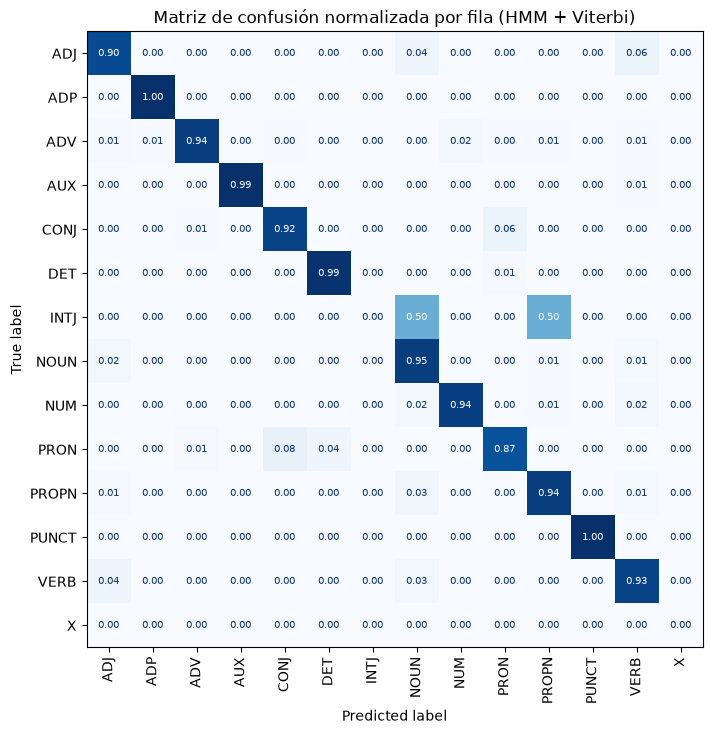

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(reales, preds, labels=ETIQUETAS, normalize="true", ax=ax,
                                        values_format=".2f", cmap="Blues", xticks_rotation=90, colorbar=False)
for texto in ax.texts:
    texto.set_fontsize(7)
ax.set_title("Matriz de confusión normalizada por fila (HMM + Viterbi)")
plt.show()

Los errores restantes son, en buena parte, ambigüedades difíciles incluso para personas: adjetivos y participios que funcionan como sustantivos, *que* como pronombre relativo frente a conjunción, nombres propios que coinciden con palabras comunes. Algunos también se deben a decisiones de anotación del corpus.

**Limitaciones del HMM como etiquetador:**

- Cada palabra se explica **solo** por su etiqueta: el modelo no puede usar a la vez la palabra, su sufijo, si tiene mayúscula, la palabra anterior y la siguiente. Tuvimos que "meter" la información de forma en el vocabulario con las clases `<UNK-...>`, un truco que no escala bien.
- Las características solapadas violan la independencia que asume el modelo generativo.

En el siguiente cuaderno veremos los **MEMM** (modelos de Markov de máxima entropía), que reemplazan $P(\text{palabra} \mid \text{etiqueta})$ por un clasificador discriminativo $P(\text{etiqueta} \mid \text{palabra, contexto, etiqueta anterior})$ con todas las características que queramos, y siguen usando **Viterbi** para decodificar.

<a id="referencias"></a>
<h2 style="color: #007ACC;">Referencias</h2>

- Jurafsky, D. & Martin, J. H. *Speech and Language Processing* (3.ª ed. borrador). [web.stanford.edu/~jurafsky/slp3](https://web.stanford.edu/~jurafsky/slp3/)
- Viterbi, A. (1967). Error bounds for convolutional codes and an asymptotically optimum decoding algorithm. *IEEE Transactions on Information Theory*, 13(2).
- Brants, T. (2000). TnT — A Statistical Part-of-Speech Tagger. *ANLP*.
- Rabiner, L. R. (1989). A Tutorial on Hidden Markov Models and Selected Applications in Speech Recognition. *Proceedings of the IEEE*, 77(2).